<a href="https://colab.research.google.com/github/Girawale-Sanket/Time-Series-Assignment/blob/main/FB_Prophet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
!pip install pystan
!pip install prophet

In [36]:
import pandas as pd
import prophet
import matplotlib.pyplot as plt
%matplotlib inline

In [37]:
data= pd.read_csv('/content/Oil.csv')

In [38]:
data

,Date,Crude_Oil_Price
0,2000-01-01,25.310000
1,2000-02-01,27.220967
2,2000-03-01,27.490000
3,2000-04-01,23.470000
4,2000-05-01,27.186667
...,...,...
310,2025-11-01,59.460000
311,2025-12-01,57.950000
312,2026-01-01,60.040000
313,2026-02-01,64.470000


In [39]:
data.isnull().sum()

,0
Date,0
Crude_Oil_Price,0


<Axes: >

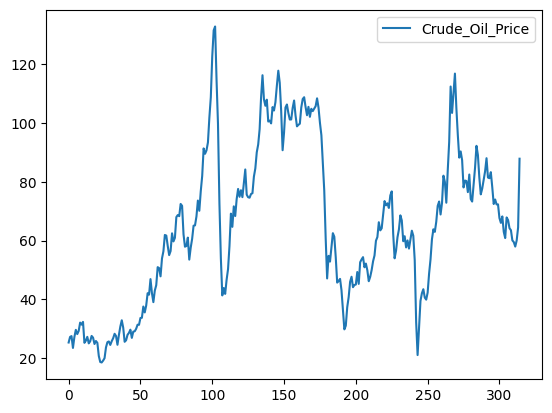

In [40]:
data.plot()

<Axes: >

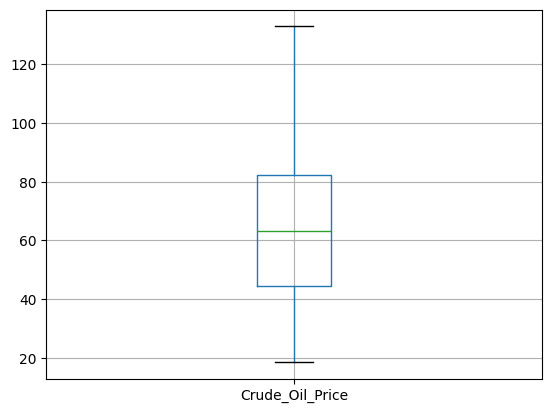

In [41]:
data.boxplot()

In [43]:
data.columns=['Date','Crude_Oil_Price']
data.head()

,Date,Crude_Oil_Price
0,2000-01-01,25.310000
1,2000-02-01,27.220967
2,2000-03-01,27.490000
3,2000-04-01,23.470000
4,2000-05-01,27.186667


In [44]:
data=data.fillna(data.mode())
data

,Date,Crude_Oil_Price
0,2000-01-01,25.310000
1,2000-02-01,27.220967
2,2000-03-01,27.490000
3,2000-04-01,23.470000
4,2000-05-01,27.186667
...,...,...
310,2025-11-01,59.460000
311,2025-12-01,57.950000
312,2026-01-01,60.040000
313,2026-02-01,64.470000


In [45]:
data.isnull().sum()

,0
Date,0
Crude_Oil_Price,0


In [46]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315 entries, 0 to 314
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Date             315 non-null    object 
 1   Crude_Oil_Price  315 non-null    float64
dtypes: float64(1), object(1)
memory usage: 5.1+ KB


In [47]:
data['Date']=pd.to_datetime(data['Date'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 315 entries, 0 to 314
Data columns (total 2 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             315 non-null    datetime64[ns]
 1   Crude_Oil_Price  315 non-null    float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 5.1 KB


In [51]:
from prophet import Prophet
model = Prophet()

In [52]:
dir(prophet)

['Prophet',
 '__all__',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '__version__',
 'diagnostics',
 'forecaster',
 'make_holidays',
 'models',
 'plot']

In [53]:
model=Prophet()

In [55]:
# Prophet requires columns to be named 'ds' and 'y'
model.fit(data.rename(columns={'Date': 'ds', 'Crude_Oil_Price': 'y'}))

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [56]:
future_dates = model.make_future_dataframe(periods=365)
future_dates.tail()

,ds
675,2027-02-25
676,2027-02-26
677,2027-02-27
678,2027-02-28
679,2027-03-01


In [57]:
prediction= model.predict(future_dates)

In [58]:
prediction.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2000-01-01,20.679472,-8.231168,41.255846,20.679472,20.679472,-3.480033,-3.480033,-3.480033,-3.480033,-3.480033,-3.480033,0.0,0.0,0.0,17.199439
1,2000-02-01,21.181559,-4.769577,42.688009,21.181559,21.181559,-1.932658,-1.932658,-1.932658,-1.932658,-1.932658,-1.932658,0.0,0.0,0.0,19.248901
2,2000-03-01,21.651253,0.097772,48.248971,21.651253,21.651253,1.177533,1.177533,1.177533,1.177533,1.177533,1.177533,0.0,0.0,0.0,22.828786
3,2000-04-01,22.153340,-1.900221,45.159467,22.153340,22.153340,0.416294,0.416294,0.416294,0.416294,0.416294,0.416294,0.0,0.0,0.0,22.569634
4,2000-05-01,22.639231,0.116304,47.268613,22.639231,22.639231,1.536290,1.536290,1.536290,1.536290,1.536290,1.536290,0.0,0.0,0.0,24.175520


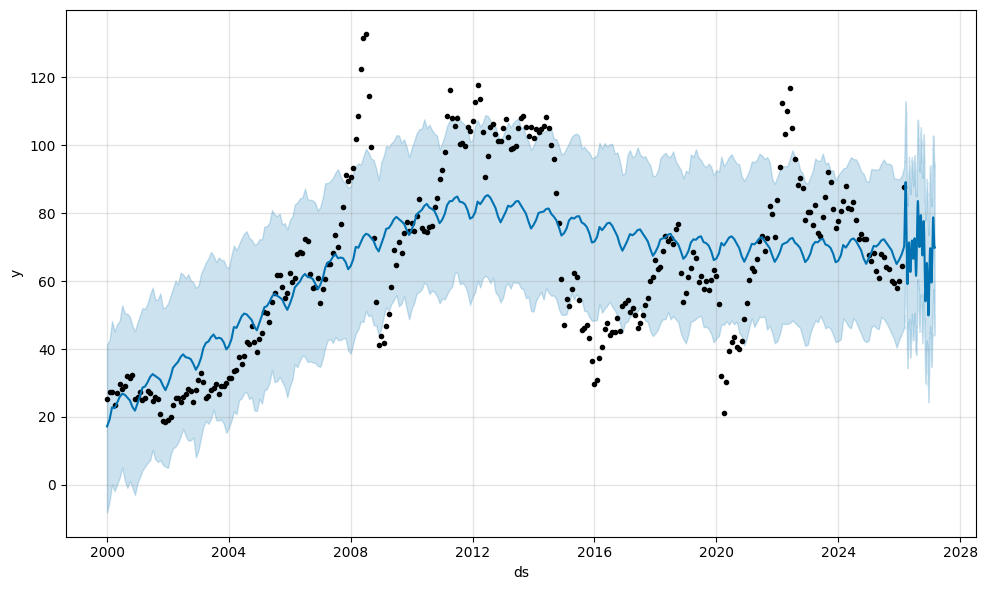

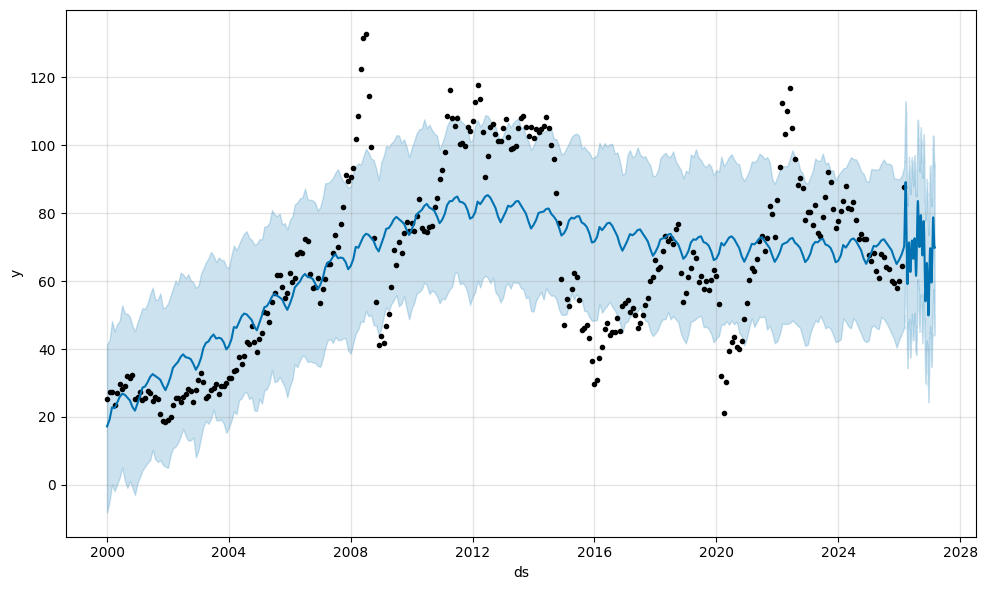

In [59]:
model.plot(prediction)

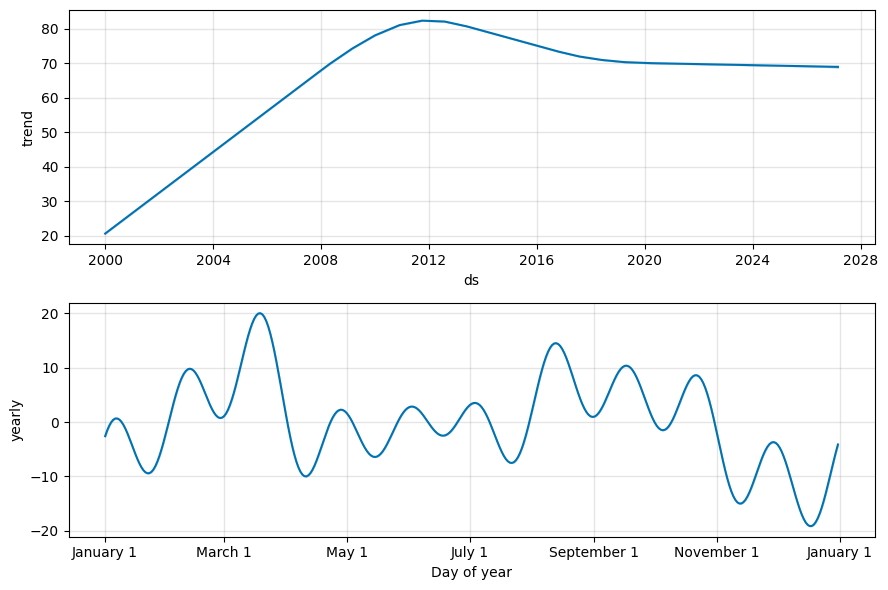

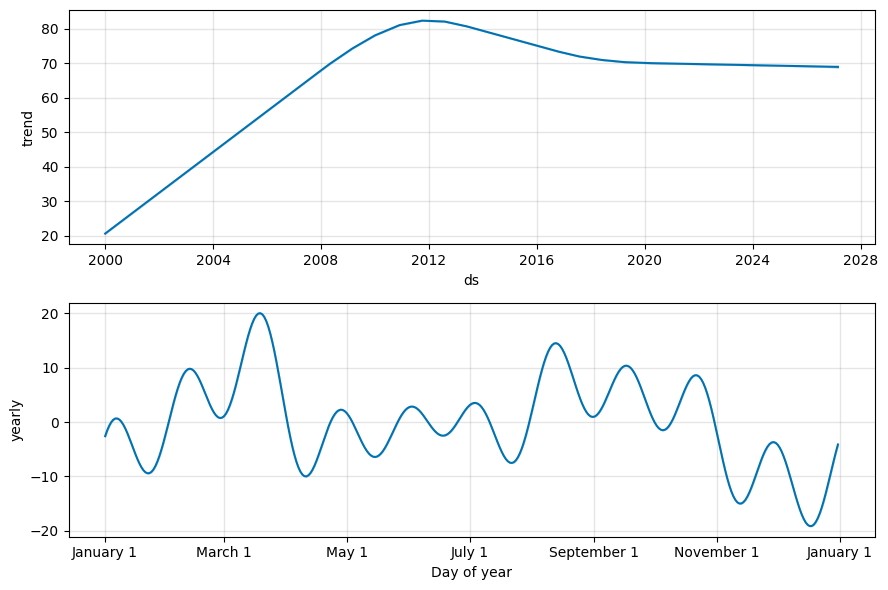

In [61]:
model.plot_components(prediction)

In [62]:
from prophet.diagnostics import cross_validation
df_cv = cross_validation(model, initial='730 days', period='180 days', horizon = '365 days')
df_cv.head()

INFO:prophet:Making 48 forecasts with cutoffs between 2002-01-01 00:00:00 and 2025-03-01 00:00:00


  0%|          | 0/48 [00:00<?, ?it/s]

INFO:prophet:n_changepoints greater than number of observations. Using 19.
INFO:prophet:n_changepoints greater than number of observations. Using 23.


,ds,yhat,yhat_lower,yhat_upper,y,cutoff
0,2002-02-01,20.357477,20.242394,20.473765,19.975237,2002-01-01
1,2002-03-01,11.272641,10.922683,11.637533,23.640667,2002-01-01
2,2002-04-01,18.732866,18.050826,19.437984,25.434242,2002-01-01
3,2002-05-01,20.238571,19.171766,21.385703,25.672345,2002-01-01
4,2002-06-01,18.259122,16.664034,19.900004,24.488058,2002-01-01


In [63]:
from prophet.diagnostics import performance_metrics
df_p = performance_metrics(df_cv)
df_p.head()

,horizon,mse,rmse,mae,mape,mdape,smape,coverage
0,37 days,536.805837,23.169071,17.290950,0.290798,0.181902,0.261977,0.508772
1,38 days,550.679698,23.466566,17.679217,0.296974,0.211120,0.266651,0.491228
2,39 days,571.068939,23.897049,17.969207,0.306177,0.211120,0.271759,0.482456
3,40 days,564.323475,23.755494,17.920878,0.308670,0.222337,0.275054,0.473684
4,41 days,556.244349,23.584833,17.614955,0.294973,0.211120,0.265393,0.491228
